# Online Retail Customer Segments
### Which customers should a business keep, win back or stop chasing?

**Tools:** Python (pandas), SQL (SQLite), Matplotlib | **Data:** [Online Retail II, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502/online+retail+ii)

## Summary

**The question:** a UK online gift shop has limited time and budget. Which customers should it focus on?

**What I did:** I cleaned 2 years of transactions, measured each customer's last purchase, number of orders and spending, and put customers into 5 simple groups. Then I tested the groups on later purchases.

| Finding | Result |
|---|---|
| **Best customers bring most of the money** | 28% of customers bring in 75% of revenue |
| **At Risk customers are worth saving** | 1,020 customers have spent £1.8M but haven't bought for 3 to 12 months |
| **A small group matters most** | The top quarter of At Risk customers (255) spent £1.2M or 64% of that group's total |
| **The groups are useful** | In a test on earlier data, 90% of Best customers bought again within 6 months, compared with 22% of Inactive customers |

**Recommendation:** protect Best customers first, contact the 255 highest-spending At Risk customers next and keep Inactive customers on low-cost contact only. Test any win-back campaign on a small group before rolling it out.

## 1. Business questions

1. How has the shop's revenue changed over time?
2. How many customers are in each group and how much do they bring in?
3. Do these groups tell us who will buy again?
4. Which At Risk customers should the team contact first?

**About the data:** transactions from a UK online gift shop, from December 2009 to December 2011. The file has one row for each product on an invoice. Amounts are in pounds.

## 2. Setup

In [1]:
import os
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

FILE = 'online_retail_II.xlsx'   # keep this file next to the notebook

COLORS = {'Best': '#1B2559', 'Regular': '#2B7A9E', 'New': '#7DB3CD', 'At Risk': '#C0272D', 'Inactive': '#8A93A6'}
ORDER = list(COLORS)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.grid.axis': 'y'})
pd.set_option('display.float_format', lambda v: f'{v:,.1f}')

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

## 3. Load and check the data

The file has one sheet for each period, so I combine them. 

In [2]:
sheets = pd.read_excel(FILE, sheet_name=None, dtype={'Invoice': str, 'StockCode': str})
raw = pd.concat(sheets.values(), ignore_index=True)

for name, sheet in sheets.items():
    print(f'{name}: {len(sheet):,} rows, {sheet["InvoiceDate"].min():%d %b %Y} to {sheet["InvoiceDate"].max():%d %b %Y}')
print(f'Combined: {len(raw):,} rows')
raw.head()

Year 2009-2010: 525,461 rows, 01 Dec 2009 to 09 Dec 2010
Year 2010-2011: 541,910 rows, 01 Dec 2010 to 09 Dec 2011
Combined: 1,067,371 rows


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,7.0,"13,085.0",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.8,"13,085.0",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.8,"13,085.0",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.1,"13,085.0",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.2,"13,085.0",United Kingdom


In [3]:
returns = raw['Invoice'].str.startswith('C')
product = raw['StockCode'].str.match(r'^\d{5}[A-Za-z]*$')

pd.DataFrame({
    'Check': ['Exact duplicate rows', 'Missing Customer ID', 'Returned items (invoice starts with C)',
              'Non-product rows (postage, fees, adjustments)', 'Zero or negative price'],
    'Rows': [raw.duplicated().sum(), raw['Customer ID'].isna().sum(), returns.sum(),
             (~product).sum(), (raw['Price'] <= 0).sum()]
}).assign(Rows=lambda t: t['Rows'].map('{:,}'.format))

,Check,Rows
0,Exact duplicate rows,"34,335"
1,Missing Customer ID,"243,007"
2,Returned items (invoice starts with C),"19,494"
3,"Non-product rows (postage, fees, adjustments)","6,094"
4,Zero or negative price,"6,207"



- **The sheets overlap:** both include 1 to 9 December 2010, so those rows appear twice. Removing exact duplicates fixes this. It also removes a few repeated rows within each sheet, which could be genuine, so this is a small assumption.
- **Missing Customer ID:** these sales can't be linked to a customer, so they can't be used here.
- **Returns:** I keep them and subtract them from spending, so a customer's total shows what they really paid.
- **Very large customers:** I keep them. They are real buyers and removing them would hide the customers who matter most.

## 4. Clean the data

In [4]:
steps = [('Original rows', len(raw))]

df = raw.drop_duplicates()
steps.append(('After removing exact duplicates', len(df)))

df = df[df['Customer ID'].notna()]
steps.append(('After removing missing Customer ID', len(df)))

df = df[df['StockCode'].str.match(r'^\d{5}[A-Za-z]*$')]
steps.append(('After keeping real products only', len(df)))

df = df[df['Price'] > 0].copy()
steps.append(('After removing zero prices', len(df)))

df['Customer ID'] = df['Customer ID'].astype(int)
df['Revenue'] = df['Quantity'] * df['Price']   # negative for returns

is_return = df['Invoice'].str.startswith('C')
print(f"Sales: £{df.loc[~is_return, 'Revenue'].sum():,.0f}")
print(f"Returns: £{df.loc[is_return, 'Revenue'].sum():,.0f} ({-df.loc[is_return, 'Revenue'].sum() / df.loc[~is_return, 'Revenue'].sum():.1%} of sales)")
print(f"Net revenue: £{df['Revenue'].sum():,.0f}")
pd.DataFrame(steps, columns=['Step', 'Rows']).assign(Rows=lambda t: t['Rows'].map('{:,}'.format))

Sales: £17,068,568
Returns: £-709,953 (4.2% of sales)
Net revenue: £16,358,615


,Step,Rows
0,Original rows,"1,067,371"
1,After removing exact duplicates,"1,033,036"
2,After removing missing Customer ID,"797,885"
3,After keeping real products only,"794,223"
4,After removing zero prices,"794,163"


## 5. Q1: How has revenue changed over time?

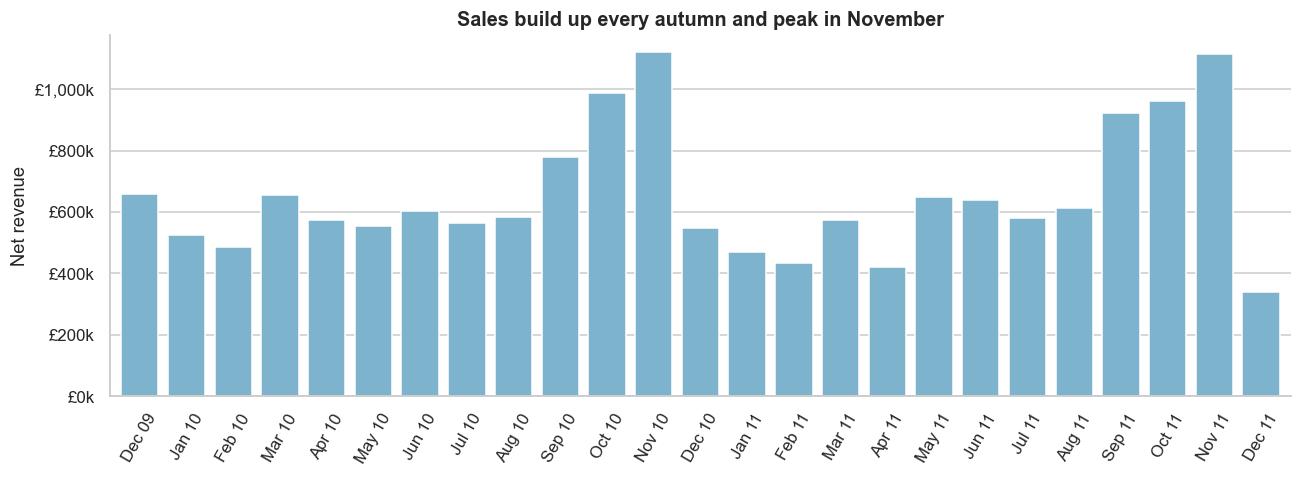

In [5]:
monthly = df.set_index('InvoiceDate')['Revenue'].resample('MS').sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(monthly.index.strftime('%b %y'), monthly.values, color='#7DB3CD')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v / 1000:,.0f}k'))
ax.set_title('Sales build up every autumn and peak in November')
ax.set_ylabel('Net revenue')
ax.tick_params(axis='x', rotation=60)
ax.margins(x=0.01)
plt.tight_layout(); plt.savefig('figures/01_monthly_revenue.png', bbox_inches='tight'); plt.show()

**Insight:** revenue peaks in November in both years, which suits a gift shop. December 2011 looks low only because the data stops on 9 December.

## 6. Q2: Customers into groups

I measure 3 things for each customer in SQL:
- **Days since last purchase:** how recently they bought.
- **Orders:** how many separate purchases they made.
- **Net spending:** what they spent, minus returns.

Then I use simple rules a manager can read:

| Group | Rule |
|---|---|
| **Best** | Bought in the last 90 days, 5 or more orders |
| **Regular** | Bought in the last 90 days, 2 to 4 orders |
| **New** | Bought in the last 90 days, 1 order |
| **At Risk** | Last bought 91 to 365 days ago, 2 or more orders |
| **Inactive** | Last bought over a year ago, or 1 order more than 90 days ago |

In [6]:
conn = sqlite3.connect(':memory:')
(df[['Invoice', 'InvoiceDate', 'Customer ID', 'Revenue']]
   .rename(columns={'Customer ID': 'customer_id', 'Invoice': 'invoice', 'InvoiceDate': 'invoice_date', 'Revenue': 'revenue'})
   .to_sql('sales', conn, index=False))

def segment_customers(as_of):
    """Groups customers using only the sales made before the as_of date."""
    return pd.read_sql_query(f'''
    WITH customer_totals AS (
        SELECT  customer_id,
                MAX(CASE WHEN invoice NOT LIKE 'C%' THEN invoice_date END)      AS last_purchase,
                COUNT(DISTINCT CASE WHEN invoice NOT LIKE 'C%' THEN invoice END) AS orders,
                SUM(revenue)                                                    AS net_spending
        FROM    sales
        WHERE   invoice_date < '{as_of}'
        GROUP BY customer_id
    ),
    with_days AS (
        SELECT  *, CAST(julianday('{as_of}') - julianday(last_purchase) AS INTEGER) AS days_since_purchase
        FROM    customer_totals
        WHERE   orders >= 1 AND ROUND(net_spending, 2) > 0
    )
    SELECT  customer_id, days_since_purchase, orders, net_spending,
            CASE WHEN days_since_purchase <= 90 AND orders >= 5 THEN 'Best'
                 WHEN days_since_purchase <= 90 AND orders >= 2 THEN 'Regular'
                 WHEN days_since_purchase <= 90                 THEN 'New'
                 WHEN days_since_purchase <= 365 AND orders >= 2 THEN 'At Risk'
                 ELSE 'Inactive' END AS segment
    FROM    with_days
    ''', conn)

customers = segment_customers('2011-12-10')   # the day after the last transaction
customers.to_sql('customers', conn, index=False)
print(f'{len(customers):,} customers grouped')
customers.head()

5,832 customers grouped


,customer_id,days_since_purchase,orders,net_spending,segment
0,12346,325,3,169.4,At Risk
1,12347,2,8,"4,921.5",Best
2,12348,75,5,"1,658.4",Best
3,12349,18,3,"3,654.5",Regular
4,12350,310,1,294.4,Lapsed


In [7]:
summary = pd.read_sql_query('''
SELECT  segment,
        COUNT(*)                                                AS customers,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)      AS pct_of_customers,
        ROUND(SUM(net_spending), 0)                             AS revenue,
        ROUND(100.0 * SUM(net_spending) / SUM(SUM(net_spending)) OVER (), 1) AS pct_of_revenue,
        ROUND(AVG(net_spending), 0)                             AS avg_spending,
        ROUND(AVG(orders), 1)                                   AS avg_orders,
        ROUND(AVG(days_since_purchase), 0)                      AS avg_days_since_purchase
FROM    customers
GROUP BY segment
''', conn).set_index('segment').loc[ORDER]
summary

,customers,pct_of_customers,revenue,pct_of_revenue,avg_spending,avg_orders,avg_days_since_purchase
segment,,,,,,,
Best,1611,27.6,"12,230,840.0",74.8,"7,592.0",15.3,26.0
Regular,906,15.5,"887,382.0",5.4,979.0,2.9,35.0
New,360,6.2,"135,365.0",0.8,376.0,1.0,44.0
At Risk,1020,17.5,"1,816,296.0",11.1,"1,781.0",5.1,199.0
Lapsed,1935,33.2,"1,291,687.0",7.9,668.0,2.0,450.0


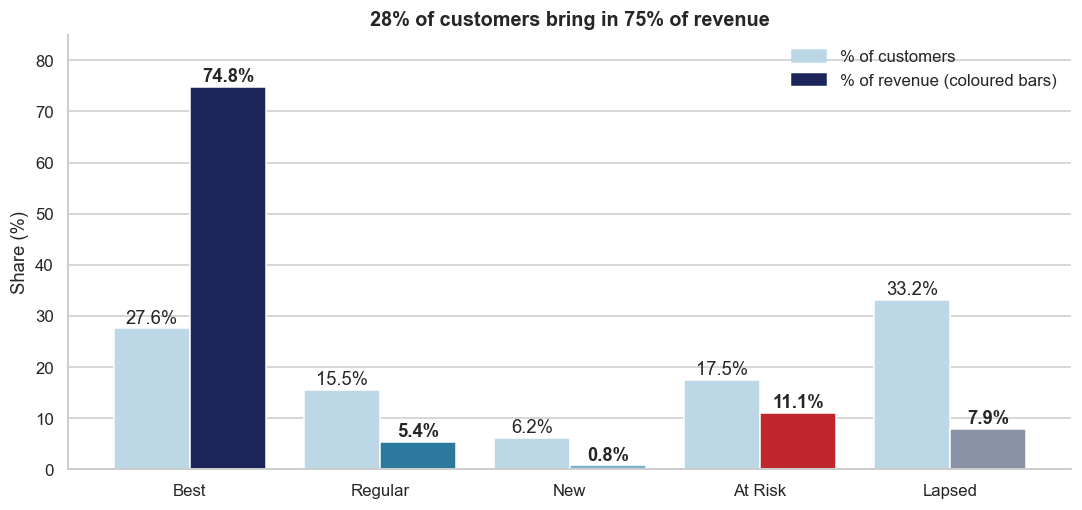

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = range(len(ORDER))
ax.bar([i - 0.2 for i in x], summary['pct_of_customers'], width=0.4, color='#BCD7E5', label='% of customers')
ax.bar([i + 0.2 for i in x], summary['pct_of_revenue'], width=0.4, color=[COLORS[s] for s in ORDER], label='% of revenue')
for i, s in enumerate(ORDER):
    ax.text(i - 0.2, summary.loc[s, 'pct_of_customers'] + 1, f"{summary.loc[s, 'pct_of_customers']:.1f}%", ha='center')
    ax.text(i + 0.2, summary.loc[s, 'pct_of_revenue'] + 1, f"{summary.loc[s, 'pct_of_revenue']:.1f}%", ha='center', fontweight='bold')
ax.set_xticks(list(x)); ax.set_xticklabels(ORDER)
ax.set_ylabel('Share (%)'); ax.set_ylim(0, 85)
ax.set_title('28% of customers bring in 75% of revenue')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#BCD7E5'), plt.Rectangle((0, 0), 1, 1, color='#1B2559')],
          labels=['% of customers', '% of revenue (coloured bars)'], frameon=False)
plt.tight_layout(); plt.savefig('figures/02_customers_vs_revenue.png', bbox_inches='tight'); plt.show()

**Insight:** Best customers are the business: they are 28% of customers and bring in 75% of revenue. At Risk customers are 17.5% of customers and 11% of revenue, about £1.8M of past spending, and they have started to go quiet. Inactive customers are the largest group, but bring in only 8%.

## 7. Q3: Do the groups tell us who will buy again?

A segmentation is only useful if it says something about the future, so I test it:

1. Go back to **9 June 2011** and group customers using only the data up to that date.
2. Look at the next **6 months** and see who actually bought again.

If the groups work, Best customers should come back much more often than Inactive customers.

In [9]:
def comeback_test(as_of, end):
    groups = segment_customers(as_of)
    later = pd.read_sql_query(f'''
        SELECT  customer_id,
                COUNT(DISTINCT CASE WHEN invoice NOT LIKE 'C%' THEN invoice END) AS later_orders,
                SUM(revenue) AS later_spending
        FROM    sales
        WHERE   invoice_date >= '{as_of}' AND invoice_date < '{end}'
        GROUP BY customer_id
    ''', conn)
    groups = groups.merge(later, on='customer_id', how='left').fillna({'later_orders': 0, 'later_spending': 0})
    groups['came_back'] = groups['later_orders'] > 0
    return groups

test = comeback_test('2011-06-09', '2011-12-09')
result = (test.groupby('segment')
              .agg(customers=('came_back', 'size'),
                   pct_came_back=('came_back', lambda s: s.mean() * 100),
                   avg_later_spending=('later_spending', 'mean'))
              .loc[ORDER])
result

,customers,pct_came_back,avg_later_spending
segment,,,
Best,1122,89.7,"2,797.5"
Regular,580,63.4,470.3
New,279,47.7,347.9
At Risk,1524,49.8,391.3
Lapsed,1421,21.5,105.5


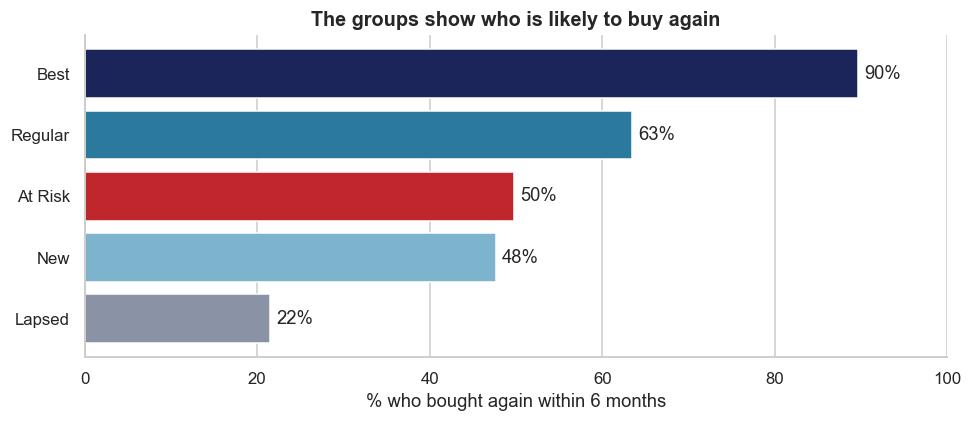

In [10]:
order = result['pct_came_back'].sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(order, result.loc[order, 'pct_came_back'], color=[COLORS[s] for s in order])
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in result.loc[order, 'pct_came_back']], padding=4)
ax.set_xlim(0, 100); ax.set_xlabel('% who bought again within 6 months')
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.set_title('The groups show who is likely to buy again')
plt.tight_layout(); plt.savefig('figures/03_comeback_test.png', bbox_inches='tight'); plt.show()

In [11]:
# Same test on an earlier date, as a second check
check = comeback_test('2010-12-09', '2011-06-09')
(check.groupby('segment')['came_back'].mean().mul(100).loc[ORDER].rename('pct_came_back').to_frame())

,pct_came_back
segment,
Best,83.3
Regular,48.6
New,25.6
At Risk,37.1
Lapsed,18.1


**Insight:** the groups work. 90% of Best customers bought again, compared with 50% of At Risk and 22% of Inactive customers. The earlier test date gives the same order, so this isn't a one-off result. The June test includes the Christmas season, so its rates are higher than usual.

This shows who came back, not why. These customers may have come back without any contact from the shop.

## 8. Q4: Which At Risk customers should the team contact first?

The team can't contact all 1,020 At Risk customers in the same way, so I split them into 4 equal groups by past spending using SQL.

In [12]:
at_risk = pd.read_sql_query('''
SELECT  customer_id, days_since_purchase, orders, ROUND(net_spending, 2) AS net_spending,
        NTILE(4) OVER (ORDER BY net_spending DESC) AS spending_group
FROM    customers
WHERE   segment = 'At Risk'
ORDER BY net_spending DESC
''', conn)

value = at_risk.groupby('spending_group').agg(customers=('customer_id', 'size'), revenue=('net_spending', 'sum'))
value['pct_of_at_risk_revenue'] = value['revenue'] / value['revenue'].sum() * 100
value.index = ['Top quarter', 'Second', 'Third', 'Lowest quarter']
value

,customers,revenue,pct_of_at_risk_revenue
Top quarter,255,"1,164,839.6",64.1
Second,255,"360,552.1",19.9
Third,255,"197,711.4",10.9
Lowest quarter,255,"93,193.1",5.1


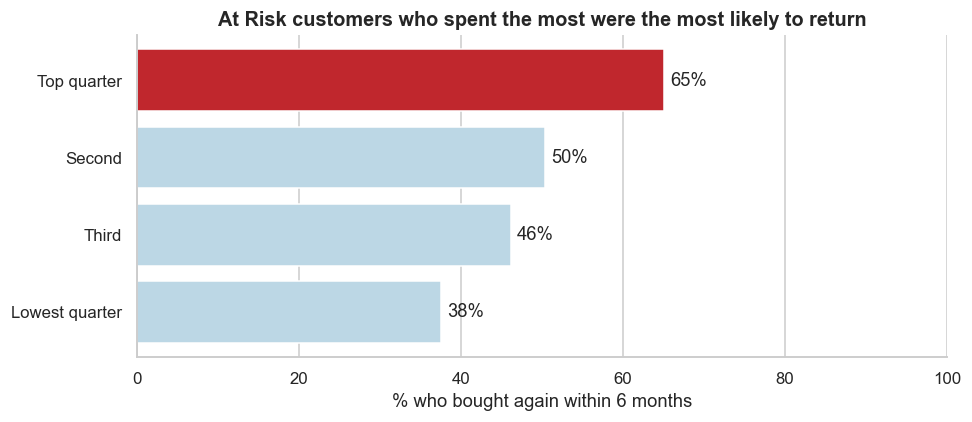

,pct_came_back
spending_group,
Lowest quarter,37.5
Third,46.2
Second,50.4
Top quarter,65.1


In [13]:
# Did big spenders in the At Risk group come back more often? Uses the June 2011 test.
past = test[test['segment'] == 'At Risk'].copy()
past['spending_group'] = pd.qcut(past['net_spending'].rank(method='first'), 4,
                                 labels=['Lowest quarter', 'Third', 'Second', 'Top quarter'])
past_result = past.groupby('spending_group', observed=True)['came_back'].mean().mul(100)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(past_result.index.astype(str), past_result.values,
               color=['#BCD7E5', '#BCD7E5', '#BCD7E5', '#C0272D'])
ax.bar_label(bars, labels=[f'{v:.0f}%' for v in past_result.values], padding=4)
ax.set_xlim(0, 100); ax.set_xlabel('% who bought again within 6 months')
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.set_title('At Risk customers who spent the most were the most likely to return')
plt.tight_layout(); plt.savefig('figures/04_at_risk_priority.png', bbox_inches='tight'); plt.show()
past_result.round(1).to_frame('pct_came_back')

**Insight:** the top quarter of At Risk customers (255 people) spent £1.2M or 64% of the group's total. In the June test, the top quarter also came back most often (65%, compared with 38% for the lowest quarter). These 255 customers are the clear place to start.

## 9. Save the results

In [14]:
summary.reset_index().to_csv('outputs/segment_summary.csv', index=False)
result.reset_index().to_csv('outputs/comeback_test.csv', index=False)
customers.round(2).to_csv('outputs/customer_segments.csv', index=False)
at_risk[at_risk['spending_group'] == 1].to_csv('outputs/at_risk_contact_first.csv', index=False)
print('Saved:', sorted(os.listdir('outputs')))
conn.close()

Saved: ['at_risk_contact_first.csv', 'comeback_test.csv', 'customer_segments.csv', 'segment_summary.csv']


## 10. Recommendations

| # | Group | What to do | Why |
|---|---|---|---|
| 1 | **Best** | Protect them first, with early access or a named contact and watch for any who stop buying | They bring in 75% of revenue |
| 2 | **At Risk** | Contact the top 255 first, using the list in `outputs/at_risk_contact_first.csv` | They spent £1.2M and 65% of this type came back in the June test |
| 3 | **New** | Encourage a second order soon after the first | About half bought again in the June test, so it's worth trying to raise that |
| 4 | **Inactive** | Use low-cost contact only, such as an occasional email | Only 22% came back and they bring in 8% of revenue |

**Before spending on win-back:** contact half of the 255 customers and hold back the other half at random. Comparing the two would show whether the contact actually changed anything.

## 11. Limitations

- **Past behaviour only:** the groups show what customers did, not why. The test shows who came back, not whether contacting them would help.
- **Customers without an ID are left out:** about 23% of rows after removing duplicates have no Customer ID, so those sales aren't included.
- **Rule cut-offs are my choice:** 90 days, 365 days and 5 orders are simple rules I chose and a business could adjust them. Changing them would change the group sizes.
- **Mostly UK, possibly wholesalers:** 84% of revenue is from the UK and some customers buy large quantities, so the results may not apply to other shops.
- **Old data:** it ends in 2011, so this shows a method, not what today's customers would do.


